# TD 1.1 : un réseau (singleton) de neurone(s)

Dans ce TD nous allons utiliser PyTorch sur un modèle très simple. Nous ne verrons qu'un réseau de neurones limité à un seul neurone. Avec en plus une fonction d'activation linéaire.

Bref, nous allons étudier la fonction $y=w.x+b$, tout simplement, où $w$ est le poids du neurone.

L'objet de ce TD est de comprendre comment fonctionne l'entraînement d'un réseau de neurones simple avec PyTorch.

## 1 Création d'un jeu de données

Il faut d'abord créer les données et importer toutes les bibliothèques. Vous allez donc voir les données que nous voulons apprendre. Il s'agit pour l'instant simplement de la fonction linéaire $y=7.x + 3$

Attention, prenez le temps de bien comprendre les dimensions des objets manipulés. Il peut s'agir pour vous de manipuler pour la première fois des matrices de Numpy.

shape of datax's : (100, 1)
shape of datay's : (100, 1)


Text(0, 0.5, 'Y (real values)')

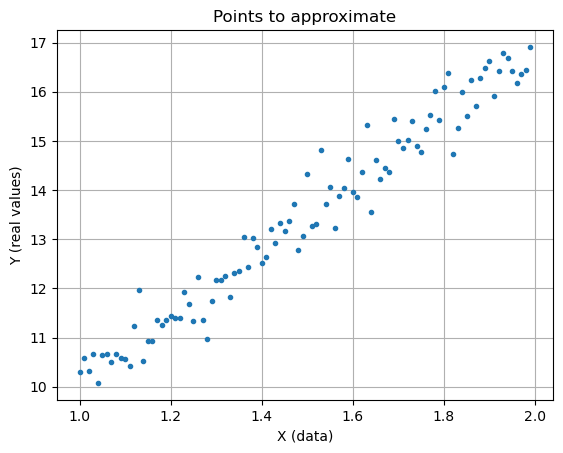

In [4]:
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
import torch
import torch.nn as nn
from torch.optim import SGD
from torch.utils.data import DataLoader, TensorDataset, random_split
from copy import deepcopy

import numpy as np

NBPOINTS = 100
# generate data
datax = np.array([(x / 100 + 1) for x in range(0, NBPOINTS)]).reshape(-1,1)
datay = datax * 7 + 3  # This applies on all the elements of the vector

# We add some noise to the perfect line
datay += np.random.normal(0, 0.35, NBPOINTS).reshape(100,1)

# We have a vector of inputs as x (the "data")... e.g. a vector of vectors (each input is a vector)
# We have a vector of outputs as y (the "function to learn") e.g. a vector of vectors of output (each output is also a vector of number)
print("shape of datax's :", datax.shape)
print("shape of datay's :", datay.shape)
plt.plot(datax, datay, '.')
plt.grid()
plt.title("Points to approximate")
plt.xlabel("X (data)"); plt.ylabel("Y (real values)")

**Prérequis**

Attention, dans ce TD nous allons approximer un nuage de point par une droite grâce à de l'apprentissage automatique. Cet exemple est uniquement pédagogique : on sait très bien (rapidement, facilement, exactement) calculer la regression linéaire $y = a.x +b$ d'un ensemble de points par la méthode des moindres carrés.

On sait que $$a = \frac{Cov(X, Y)}{Var(X)}$$ et $$b = \overline{Y} - a.\overline{X}$$

Donc si on voulait vraiment simplement calculer la regression linéaire des points ci-dessus *on n'utiliserait pas de l'apprentissage automatique** mais le petit programme ci-dessous :

Text(0, 0.5, 'Y (real values)')

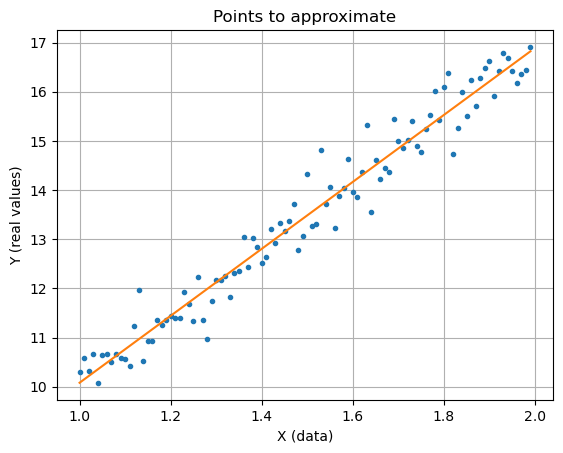

In [5]:
# Covariance
def covariance(X, Y):
  assert len(X) > 0 and len(X) == len(Y)
  y_avg = sum(Y) / len(Y)
  x_avg = sum(X) / len(X)
  return sum([(X[i] - x_avg) * (Y[i] - y_avg) for i in range(len(X))]) / len(X)

#variance
def variance(X):
  assert len(X) > 0
  return sum([x**2 for x in X]) / len(X) - (sum(X) / len(X)) ** 2

a = covariance(datax, datay) / variance(datax)
b = sum(datay) / len(datay) - a * (sum(datax) / len(datax))

plt.plot(datax, datay, '.')
plt.plot(datax, [a * x + b for x in datax])
plt.grid()
plt.title("Points to approximate")
plt.xlabel("X (data)"); plt.ylabel("Y (real values)")

## 2 Faire du Machine Learning sans Pytorch

Dans ce permier exercice, nous allons reprendre la fonction de Loss vue en cours pour ce problème et le calcul de la dérivée par rapport à $a$ et $b$ pour simuler un apprentissage automatique sans outils.



In [6]:
shuffled = datax.copy()
np.random.shuffle(shuffled)
sizetraining = int(len(shuffled) * 0.66)
train = shuffled[:sizetraining]
val = shuffled[sizetraining:]
# For simplicity, I will just use the equation y = x * 7 +3 each time I need a truth value for a x

w = np.random.random_sample() # Initial values ()
b = np.random.random_sample()
learning_rate = 0.001

for epoch in range(20):
  sumloss = 0
  np.random.shuffle(train) # Reorder examples at each epoch
  for x in train:
    y_hat = x * w + b # predicted value
    y = x * 7 + 3     # true value

    loss = (y_hat - y) ** 2 # Loss = (y_hat - y)^2
    sumloss += loss

    db = 2 * (y_hat - y) 
    dw = 2 * x * (y_hat - y)

    # This is the learning part
    w += -learning_rate * dw
    b += -learning_rate * db

  # Now evaluating on validation data
  sumlossval = 0
  for x in val:
    y_hat = x * w + b # predicted value
    y = x * 7 + 3     # true value

    loss = (y_hat - y) ** 2 # Loss = (y_hat - y)^2
    sumlossval += loss

  print("loss: ", sumloss / len(train), "loss val:", sumlossval / len(train), " w:", w, " b: ", b)


loss:  [96.30279573] loss val: [28.66187916]  w: [2.84370468]  b:  [1.68716783]
loss:  [39.62989807] loss val: [11.74016593]  w: [4.11506256]  b:  [2.4983598]
loss:  [16.31464085] loss val: [4.79578804]  w: [4.93051976]  b:  [3.02032019]
loss:  [6.72779703] loss val: [1.96045583]  w: [5.45403137]  b:  [3.35164083]
loss:  [2.78608979] loss val: [0.80022357]  w: [5.79074469]  b:  [3.5644556]
loss:  [1.16384656] loss val: [0.33030563]  w: [6.00691747]  b:  [3.69902325]
loss:  [0.49692446] loss val: [0.13962629]  w: [6.14681734]  b:  [3.78501945]
loss:  [0.22203632] loss val: [0.06392035]  w: [6.23690865]  b:  [3.83874392]
loss:  [0.10877319] loss val: [0.03413564]  w: [6.29557307]  b:  [3.8723461]
loss:  [0.06235198] loss val: [0.02293471]  w: [6.33343983]  b:  [3.89247494]
loss:  [0.04311927] loss val: [0.01885264]  w: [6.35836725]  b:  [3.90431424]
loss:  [0.03507226] loss val: [0.01746364]  w: [6.37535641]  b:  [3.91108405]
loss:  [0.03161513] loss val: [0.01708914]  w: [6.38631051]  b

## 2 Préparation du modèle en PyTorch

L'apprentissage peut se faire exemple après exemple, mais également par groupe d'exemples (des batchs). L'avantage de l'utilisation de batch est multiple : cela permet par exemple de trouver immédiatement comment faire évoluer le réseau de neurones pour un ensemble de points. Cela permet également de jouer sur la performance des CPU et des GPU à paralleliser du code concernant des opérations matricielles. En interne, cela ajoute une dimension à toutes les opérations : le réseau apprend en même temps avec plusieurs exemples à la fois.

**Vous devez passer un peu de temps sur la documentation PyTorch**

- Compléter la classe `LinearModel` de manière à créer un réseau de neurones ayant un seul neurone
    
- La fonction `getwb(layer)` permet de récupérer les valeurs des poids et biais d'une couche de neurones. Dans notre cas, cela permet de retourner `w` et `b` dans l'équation `y=w.x+b`

In [7]:
def getwb(model):
    params = model.parameters()
    [tmpw, tmpb] = next(params).item(), next(params).item()
    return (tmpw, tmpb)

# Define the model: Just one neuron!!
class LinearModel(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.nn = nn.Sequential(
            nn.Linear(1,1), 
        )

    def forward(self, x):
        x = self.nn(x)
        return x

## 3 Entraînement du modèle

Compléter la cellule ci-dessous afin d'appeler la fonction `train` avec les bons paramètres.
Vous devez :
- fournir en entrée les données au bon format et le modèle
- définir les hyperparamètres de l'apprentissage (taille de batch, nombre d'epochs, etc.)
- définir un `optimizer` (utiliser la descente de gradient stochastique)
- définir une *loss function* (`criterion`)
- définir une métrique d'évaluation de la qualité des prédictions (`metric`, peut être la même que la *loss function* dans ce cas)

In [8]:
# Training loop function
def train(tensorx, tensory, batch_size, epochs, model, criterion, optimizer, metric, validation_split):
    train_index, valid_index = random_split(range(len(tensory)), [1-validation_split, validation_split])

    x_train, x_valid = tensorx[train_index], tensorx[valid_index]
    y_train, y_valid = tensory[train_index], tensory[valid_index]

    train_set = TensorDataset(x_train, y_train)
    valid_set = TensorDataset(x_valid, y_valid)
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    valid_loader = DataLoader(valid_set, batch_size=batch_size, shuffle=False)

    history = {'w': [], 'b': [], 'loss': [], 'val_loss': [], 'score': [], 'val_score': [], 'batchHistory': []}

    for epoch in range(epochs):
        train_loss = 0.0
        train_score = 0.0
        valid_loss = 0.0
        valid_score = 0.0
        for x, y in train_loader:
            train_pred = model(x)
            loss = criterion(train_pred, y)
            score = metric(train_pred, y)
            train_loss += loss.item()
            train_score += score.item()

            model.zero_grad()
            loss.backward()
            optimizer.step()
            history['batchHistory'].append([x.item() for x in list(model.parameters())])

        with torch.no_grad():
            for x, y in valid_loader:
                valid_pred = model(x)
                loss = criterion(valid_pred, y)
                score = metric(valid_pred, y)
                valid_loss += loss.item()
                valid_score += score.item()

        params = list(model.parameters())
        history['w'].append(params[0].item())
        history['b'].append(params[1].item())
        history['loss'].append(train_loss)
        history['score'].append(train_score)
        history['val_loss'].append(valid_loss)
        history['val_score'].append(valid_score)
        print(f"Epoch {epoch+1:>4}/{epochs} - loss : {train_loss:>9.3f} - score : {train_score:>9.3f} - val_loss : {valid_loss:>9.3f} - val_score : {valid_score:>9.3f}")

    return history

model = LinearModel()

print(model)
print("Values of the neuron before learning :", getwb(model))

# A remplir ici
################################################# ICI :
batch_size = 3
epochs = 20
optimizer = SGD(model.parameters(), lr=0.001)
criterion = nn.MSELoss()
metric = criterion

history = train(torch.Tensor(datax), torch.Tensor(datay), batch_size, epochs, model, criterion, optimizer, metric, 0.33)

print("Values of the neuron after learning :", getwb(model))

LinearModel(
  (nn): Sequential(
    (0): Linear(in_features=1, out_features=1, bias=True)
  )
)
Values of the neuron before learning : (0.9461245536804199, 0.7980808019638062)
Epoch    1/20 - loss :  2594.438 - score :  2594.438 - val_loss :  1019.692 - val_score :  1019.692
Epoch    2/20 - loss :  1911.119 - score :  1911.119 - val_loss :   751.588 - val_score :   751.588
Epoch    3/20 - loss :  1423.031 - score :  1423.031 - val_loss :   552.227 - val_score :   552.227
Epoch    4/20 - loss :  1063.401 - score :  1063.401 - val_loss :   404.216 - val_score :   404.216
Epoch    5/20 - loss :   767.972 - score :   767.972 - val_loss :   297.045 - val_score :   297.045
Epoch    6/20 - loss :   562.226 - score :   562.226 - val_loss :   218.749 - val_score :   218.749
Epoch    7/20 - loss :   418.119 - score :   418.119 - val_loss :   161.012 - val_score :   161.012
Epoch    8/20 - loss :   304.486 - score :   304.486 - val_loss :   119.001 - val_score :   119.001
Epoch    9/20 - loss : 

## 4 Essayez différentes techniques

Utilisez toutes les cellules ci-dessous pour visualiser comment le réseau converge et apprend.
- Notez à quelle vitesse les valeurs `w` et `b` convergent vite
- Notez également à quel moment les valeurs se stabilisent

**Différentes techniques à essayer**
- quel impact a le *learning rate* (essayez `0.1, 0.3, 0.05, ...`) sur les figures ci-dessous ?
- quel impact a le *batch_size* sur le temps et les figures ?
- changez la heatmap pour afficher seulement le log du loss plutot que le loss

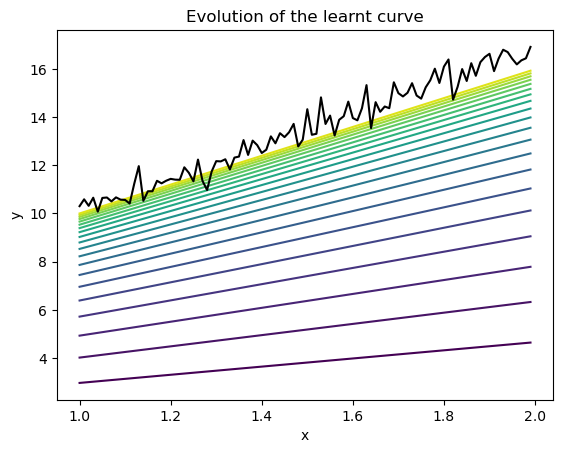

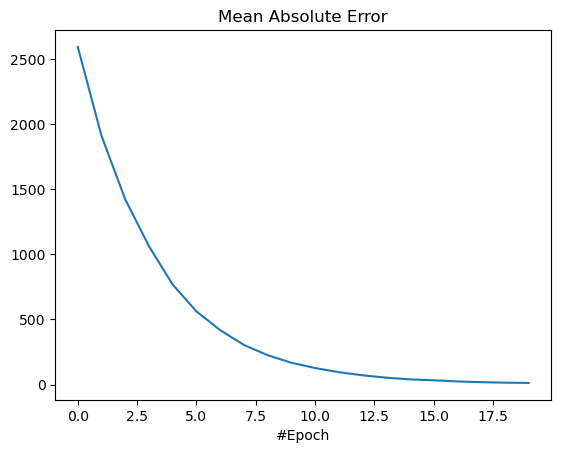

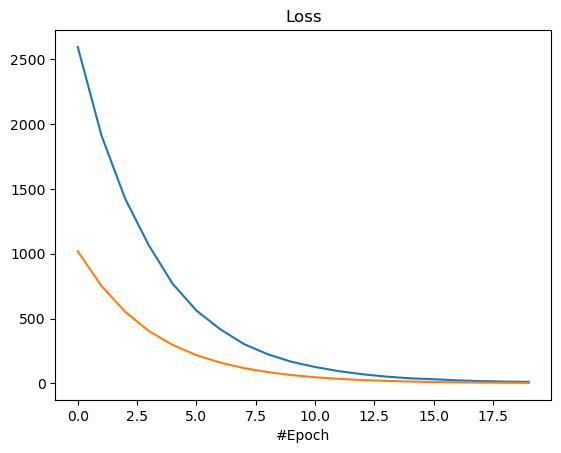

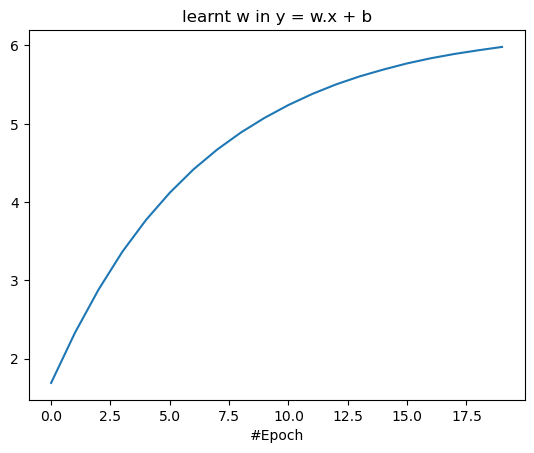

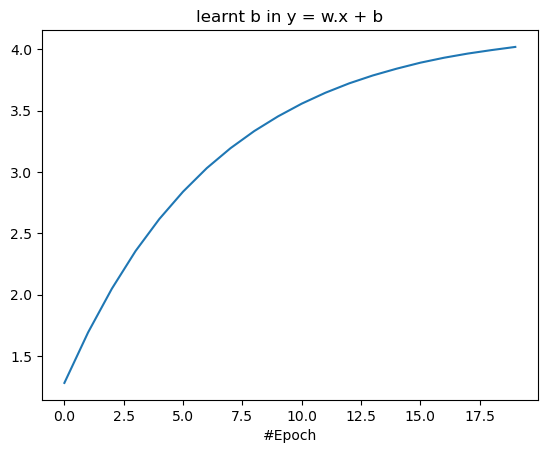

In [12]:
cmap = matplotlib.colormaps.get_cmap('viridis')

n = 0
plt.figure(n); n+=1
plt.title("Evolution of the learnt curve")
plt.xlabel("x")
plt.ylabel("y")
wtmp = history['w']
btmp = history['b']
for i, w in enumerate(wtmp):
    out = datax * w + btmp[i] # Gives what the model predicted for all outputs at epoch i
    # in fact this is exactly what model.predict(datax) would have given us after this epoch
    plt.plot(datax, out, color=cmap(i/epochs))
plt.plot(datax,datay,'k') # Plots the initial data

# Use the model

plt.figure(n); n+=1
plt.title("Mean Absolute Error")
plt.xlabel("#Epoch")
plt.plot(history['score'])

plt.figure(n); n+=1
plt.title("Loss")
plt.xlabel("#Epoch")
plt.plot(history['loss'])
plt.plot(history['val_loss'])

plt.figure(n); n+=1
plt.title("learnt w in y = w.x + b")
plt.xlabel("#Epoch")
plt.plot(history['w'])

plt.figure(n); n+=1
plt.title("learnt b in y = w.x + b")
plt.xlabel("#Epoch")
plt.plot(history['b'])

#### Affichage simple de l'équation apprise

In [13]:
[w,b] = getwb(model)
print("y={}.x + {}".format(w, b))

y=5.981649875640869.x + 4.020254611968994


### Construction des valeurs de la heatmap

In [14]:
ws = (min(history['w'])-1, max(history['w'])+1)
print("Values of w's are inside {}".format(ws))
bs = (min(history['b'])-1, max(history['b'])+1)
print("Values of b's are inside {}".format(bs))

# Very simple loss computation... Can be done with numpy much more efficiently
def getloss(X, Y, w, b):
    totalLoss = 0
    for i, x in enumerate(X): 
        xx = x[0]
        my = xx * w + b
        loss = abs(my-Y[i][0])
        loss *= loss
        totalLoss += loss
    return totalLoss / len(X)

RESOLUTION = 100 # The map will be 100x100
hmap = np.zeros((RESOLUTION,RESOLUTION))
xticks = np.linspace(ws[0], ws[1], RESOLUTION, endpoint=False)
yticks = np.linspace(bs[0], bs[1], RESOLUTION, endpoint=False)
xi = 0
for xx in xticks:
    yi = 0
    for yy in yticks:
        hmap[yi, xi] = np.log(getloss(datax, datay, xx, yy))
        yi += 1
    xi += 1
getloss(datax,datay,7,3)

Values of w's are inside (0.6910022497177124, 6.981649875640869)
Values of b's are inside (0.27963948249816895, 5.020254611968994)


np.float64(0.16033927680144766)

### Affichage de la HeatMap du loss

Cette partie permet de voir l'évolution des valeurs `w` et `b` au cours de l'apprentissage, en représentant les valeurs après chaque *batch* et/ou après chaque *epoch*

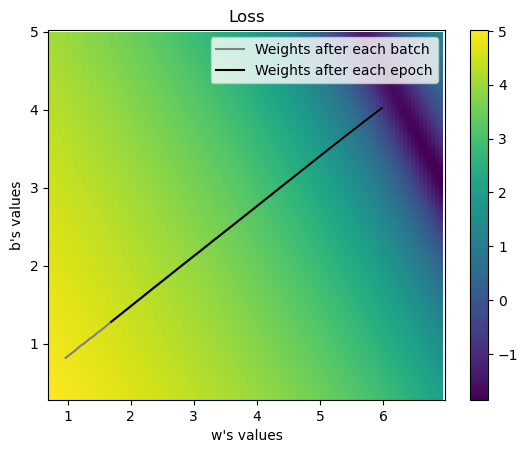

In [15]:
# Getting a picture of the moves of the search
fig, ax = plt.subplots()

minz = hmap.min()
maxz = hmap.max()
c = ax.pcolormesh(xticks, yticks, hmap, cmap='viridis', vmin=minz, vmax=maxz)
ax.set_title('Loss')
plt.xlabel('w\'s values')
plt.ylabel('b\'s values')
# set the limits of the plot to the limits of the data
ax.axis([ws[0], ws[1], bs[0], bs[1]])
fig.colorbar(c, ax=ax)
plt.plot([x[0] for x in history['batchHistory']], [x[1] for x in history['batchHistory']], color='gray')
plt.plot([xx for xx in history['w']], [xx for xx in history['b']], color='black')
plt.legend(['Weights after each batch', 'Weights after each epoch'])
plt.show()